# Haar + LBF 68 landmark + LBP–HSV + SVM
Notebook baru ini memakai **OpenCV Facemark LBF**, yaitu metode landmark klasik
tanpa deep learning. Tidak ada import Dlib atau MediaPipe.

**Alur:** foto → crop Haar → landmark LBF → mask → LBP–HSV → scaler → SVM.
Crop Haar, margin 15%, resize maksimal 384, split data, fitur, dan tuning sama
dengan eksperimen sebelumnya. Bagian landmark diganti dengan LBF.

**LBF berbeda dengan LBP:** LBF mencari titik wajah; LBP merangkum tekstur.

| Bagian | Pengaturan |
|---|---|
| Fitur pembanding | LBP radius 1 + HSV = 58 fitur |
| Fitur multi-radius | LBP radius 1,2,3 + HSV = 102 fitur |
| Tuning SVM | C–gamma, 5-fold cross-validation pada train |
| Evaluasi | Validation yang sama; test tidak dibaca |
| Hasil baru | `results_lbf_multiradius/` |

Pilih kernel **Python (ACNE04 Landmark)**, siapkan langkah 0, lalu Run All.
Notebook ini mandiri saat dijalankan; tidak perlu menjalankan notebook lama.
Model sebelumnya tidak ditimpa. Mask berubah sehingga fitur harus dihitung ulang
dan SVM dilatih ulang. Peningkatan skor tidak dijamin.

**Status:** struktur dan logika notebook dapat diperiksa tanpa model, tetapi
deteksi LBF asli dan training penuh memerlukan file `lbfmodel.yaml`.
Tidak ada skor LBF yang diklaim sebelum eksperimen dijalankan.

## 0. Siapkan model landmark sekali saja
Environment proyek sudah memiliki OpenCV contrib 4.11 dan API LBF. Jalankan
perintah berikut pada terminal lokal dari root proyek untuk mengunduh model:

```powershell
experiments/acne04_landmark/.venv/Scripts/python.exe experiments/acne04_landmark/download_lbf_model.py
```

Model disimpan di `experiments/acne04_landmark/lbf_models/lbfmodel.yaml`.
Jika sudah memiliki file tersebut, letakkan pada lokasi ini; tidak perlu unduh ulang.
File yang digunakan berasal dari tautan pretrained pada
[tutorial Facemark OpenCV](https://legacy-docs.opencv.org/4.x/d7/dec/tutorial_facemark_usage.html).

Jika `cv2.face.createFacemarkLBF` tidak tersedia pada komputer lain, gunakan
environment dengan `opencv-contrib-python==4.11.0.86`, seperti requirements proyek.
Restart kernel setelah mengganti paket. Tidak diperlukan Dlib, MediaPipe, atau GPU.

Model LBF sudah dilatih. Di notebook ini `facemark.fit()` berarti **mencocokkan
landmark pada foto**, bukan melatih ulang model LBF. Yang dilatih adalah SVM.

## 1. Import library
`cv2` menangani Haar, LBF dan mask; `numpy` menangani array piksel; `sklearn`
menyediakan scaler, SVM dan evaluasi. Tidak ada dependensi neural network.

In [1]:
from pathlib import Path
import json
import hashlib
import importlib.metadata
import platform

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from PIL import Image, ImageOps
from skimage.feature import local_binary_pattern
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from IPython.display import display

assert hasattr(cv2, 'CascadeClassifier'), 'Pilih kernel Python (ACNE04 Landmark).'
cv2.setNumThreads(1)
print('OpenCV:', cv2.__version__)
assert hasattr(cv2, 'face') and hasattr(cv2.face, 'createFacemarkLBF'), \
    'API LBF tidak ada. Pilih kernel Python (ACNE04 Landmark) dengan OpenCV contrib.'

OpenCV: 4.11.0


## 2. Folder, data dan parameter
Satu baris manifest adalah satu foto. Label 0–3 berarti ringan, sedang, berat,
sangat berat. Pemisahan train/validation mengikuti manifest lama.

Setelah crop awal, Haar mencari kotak wajah **di dalam crop** untuk diberikan
kepada LBF. LBF membutuhkan kotak wajah dan tidak mencari wajah sendiri.
Maksimal dua kotak terbesar dicocokkan; kontur valid terluas dipilih.
Parameter ini tetap dan tidak dipilih berdasarkan hasil validation.

In [2]:
ROOT = Path.cwd()
while not (ROOT / 'ACNE04-Preprocessed').exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError('Buka notebook dari dalam folder proyek machine_learning.')
    ROOT = ROOT.parent

PROJECT = ROOT / 'experiments/acne04_landmark'
DATA = ROOT / 'ACNE04-Preprocessed'
RAW = ROOT / 'ACNE04-Dataset/Images'
PREVIOUS = ROOT / 'experiments/acne04_classical/results'
OLD_RESULTS = PROJECT / 'results_multiradius'
OUT = PROJECT / 'results_lbf_multiradius'
OUT.mkdir(exist_ok=True)
(OUT / 'models').mkdir(exist_ok=True)

rows = pd.read_csv(PREVIOUS / 'manifest_with_roi.csv')
rows = rows.loc[rows['split'].isin(['train', 'val'])].reset_index(drop=True)
assert rows['filename'].is_unique
assert rows['sha256'].is_unique, 'Ada gambar duplikat antarbaris.'
assert set(rows['label']) == {0, 1, 2, 3}
assert set(rows['split']) == {'train', 'val'}

classes = ['mild', 'moderate', 'severe', 'very_severe']
CONFIG = {
    'max_num_faces': 2,
    'forehead_ratio': 0.25,
}
RADIUS_OPTIONS = {'single_radius': [1], 'multi_radius': [1, 2, 3]}
cascade_path = Path(cv2.data.haarcascades) / 'haarcascade_frontalface_default.xml'
detector = cv2.CascadeClassifier(str(cascade_path))
assert not detector.empty(), 'File Haar Cascade gagal dimuat.'

display(pd.crosstab(rows['split'], rows['label']))
(OUT / 'masks').mkdir(exist_ok=True)
MODEL_PATH = PROJECT / 'lbf_models/lbfmodel.yaml'
if not MODEL_PATH.is_file():
    raise FileNotFoundError('Model LBF belum ada. Jalankan download_lbf_model.py sesuai langkah 0.')

facemark = cv2.face.createFacemarkLBF()
facemark.loadModel(str(MODEL_PATH))
print('Model LBF berhasil dimuat:', MODEL_PATH.name)

label,0,1,2,3
split,,,,
train,349,425,123,90
val,75,91,27,19


Model LBF berhasil dimuat: lbfmodel.yaml


## 3. Baca foto dan crop Haar
Fungsi ini sama seperti sebelumnya: JPEG draft 768 → koreksi EXIF → RGB →
Haar pada grayscale maksimal 640 → kotak terbesar → margin 15% → crop RGB →
resize proporsional maksimal 384 tanpa padding.

Haar memakai `scaleFactor=1.1`, `minNeighbors=5`, minimum 40×40.
Jika gagal, baseline yang sudah dibuang padding-nya dipakai sebagai fallback.
Fungsi mengembalikan crop, pratinjau, dan catatan deteksi.

In [3]:
def baseline_image(row):
    image_path = DATA / row['rgb_path']
    with Image.open(image_path) as source:
        image = np.array(source.convert('RGB'))

    left = int(row['roi_left'])
    top = int(row['roi_top'])
    width = int(row['roi_width'])
    height = int(row['roi_height'])
    return image[top:top + height, left:left + width].copy()

In [4]:
def box_area(box):
    return int(box[2]) * int(box[3])


def detect_and_crop(row):
    with Image.open(RAW / row['filename']) as source:
        source.draft('RGB', (768, 768))
        original = ImageOps.exif_transpose(source).convert('RGB')

    small = ImageOps.contain(original, (640, 640))
    small_rgb = np.array(small)
    gray = cv2.cvtColor(small_rgb, cv2.COLOR_RGB2GRAY)
    boxes = detector.detectMultiScale(
        gray, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40))
    preview = small_rgb.copy()

    if len(boxes) == 0:
        info = {'detected': False, 'box_count': 0, 'crop_fraction': 1.0, 'box': ''}
        return baseline_image(row), preview, info

    x, y, width, height = max(boxes, key=box_area)
    cv2.rectangle(preview, (int(x), int(y)),
                  (int(x + width), int(y + height)), (0, 255, 0), 2)

    # Petakan batas kotak dari gambar kecil ke foto RGB, dengan margin 15%.
    left = max(0, int((x - 0.15 * width) * original.width / small.width))
    top = max(0, int((y - 0.15 * height) * original.height / small.height))
    right = min(original.width, int(np.ceil((x + 1.15 * width) * original.width / small.width)))
    bottom = min(original.height, int(np.ceil((y + 1.15 * height) * original.height / small.height)))

    crop = original.crop((left, top, right, bottom))
    crop = ImageOps.contain(crop, (384, 384), Image.Resampling.LANCZOS)
    info = {
        'detected': True,
        'box_count': len(boxes),
        'crop_fraction': (right - left) * (bottom - top) / (original.width * original.height),
        'box': str([left, top, right, bottom]),
    }
    return np.array(crop), preview, info

### 3.1 Mask efektif dan fallback
Mask putih (255) memilih piksel dan hitam (0) mengeluarkannya. Erosi 3×3
memeriksa interior mask. Jika interior kurang dari 100 piksel, gunakan seluruh
crop. Fungsi ini sama dengan eksperimen sebelumnya.

In [5]:
def effective_mask(image, mask):
    assert mask.dtype == np.uint8
    assert mask.shape == image.shape[:2]
    kernel = np.ones((3, 3), dtype=np.uint8)
    interior = cv2.erode(mask, kernel, borderType=cv2.BORDER_CONSTANT, borderValue=0)
    fallback = np.count_nonzero(interior) < 100

    if fallback:
        mask = np.full(image.shape[:2], 255, dtype=np.uint8)
    return mask, fallback

## 4. Bentuk mask dari 68 titik
Model LBF ini menggunakan susunan 68 titik yang sama untuk bagian wajah berikut:

| Titik Python | Bagian |
|---|---|
| 0–16 | Rahang |
| 17–26 | Alis |
| 27–35 | Hidung, dikeluarkan dari mask |
| 36–47 | Mata |
| 48–59 | Batas luar bibir |

**Dahi diperkirakan**, karena tidak ada titik kontur dahi lengkap. Ambil titik alis
dalam urutan terbalik dan geser ke atas sebesar 25% jarak vertikal rata-rata alis
ke dagu. Sambungkan dengan rahang untuk membentuk poligon wajah.
Ini asumsi geometris tetap, bukan batas kulit yang pasti.

Mata, alis, hidung, dan bibir dikeluarkan dengan convex hull (bidang pembungkus titik).
Mask tidak memakai threshold warna kulit. Periksa dahi, rambut, dan wajah profil.

In [6]:
def mask_from_points(image_shape, points):
    height, width = image_shape[:2]
    jaw = points[0:17]

    # LBF 68 tidak punya titik kontur dahi: buat batas atas perkiraan dari alis.
    eyebrows = points[17:27]
    eyebrow_y = float(np.mean(eyebrows[:, 1]))
    chin_y = float(points[8, 1])
    face_height = max(1.0, chin_y - eyebrow_y)
    forehead = eyebrows[::-1].copy()
    upward_shift = int(round(CONFIG['forehead_ratio'] * face_height))
    forehead[:, 1] = forehead[:, 1] - upward_shift

    contour = np.vstack([jaw, forehead]).astype(np.int32)
    contour[:, 0] = np.clip(contour[:, 0], 0, width - 1)
    contour[:, 1] = np.clip(contour[:, 1], 0, height - 1)
    mask = np.zeros((height, width), dtype=np.uint8)
    cv2.fillPoly(mask, [contour], 255)

    excluded_regions = [points[36:42], points[42:48],
                        points[17:22], points[22:27], points[27:36], points[48:60]]
    for region in excluded_regions:
        hull = cv2.convexHull(region)
        cv2.fillConvexPoly(mask, hull, 0)
    return mask, contour

### 4.1 Temukan titik LBF di dalam crop
Haar menyediakan kotak `(x, y, lebar, tinggi)` pada crop. `facemark.fit()`
mengembalikan status dan titik landmark pada koordinat piksel.
Koordinat diperiksa, dibulatkan, dan dibatasi pada ukuran crop.

Jika tidak ada wajah, fitting gagal, geometri tidak valid atau mask terlalu kecil,
seluruh crop dipakai dan alasannya dicatat. Error pemuatan model/runtime tidak
disembunyikan sebagai deteksi gagal. Semua gambar tetap masuk evaluasi.

In [7]:
def landmark_mask(image):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    boxes = detector.detectMultiScale(
        gray, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40))
    info = {
        'landmark_face_count': len(boxes),
        'landmark_detected': False,
        'landmark_fallback': True,
        'landmark_raw_fraction': 0.0,
        'landmark_reason': 'no_face',
    }
    full_mask = np.full(image.shape[:2], 255, dtype=np.uint8)
    if len(boxes) == 0:
        return full_mask, info, None

    selected_boxes = sorted(boxes, key=box_area, reverse=True)
    selected_boxes = selected_boxes[:CONFIG['max_num_faces']]
    rectangles = np.array(selected_boxes, dtype=np.int32).reshape(-1, 4)
    success, landmarks = facemark.fit(gray, rectangles)
    if not success or landmarks is None:
        info['landmark_reason'] = 'fit_failed'
        return full_mask, info, None

    height, width = image.shape[:2]
    selected_points = None
    selected_mask = None
    largest_area = 0
    for face_points in landmarks:
        coordinates = np.asarray(face_points, dtype=float)
        if coordinates.size != 136 or not np.isfinite(coordinates).all():
            continue
        points = np.rint(coordinates.reshape(68, 2)).astype(np.int32)
        points[:, 0] = np.clip(points[:, 0], 0, width - 1)
        points[:, 1] = np.clip(points[:, 1], 0, height - 1)
        raw_mask, contour = mask_from_points(image.shape, points)
        area = abs(cv2.contourArea(contour))
        if area > largest_area:
            largest_area = area
            selected_points = points
            selected_mask = raw_mask

    if selected_points is None:
        info['landmark_reason'] = 'invalid_geometry'
        return full_mask, info, None

    mask, fallback = effective_mask(image, selected_mask)
    info['landmark_detected'] = True
    info['landmark_fallback'] = bool(fallback)
    info['landmark_raw_fraction'] = float(np.mean(selected_mask > 0))
    if fallback:
        info['landmark_reason'] = 'small_mask'
    else:
        info['landmark_reason'] = 'ok'
    return mask, info, selected_points


def overlay_mask(image, mask):
    overlay = image.copy()
    selected = mask > 0
    green = np.array([0, 255, 0])
    overlay[selected] = (0.65 * image[selected] + 0.35 * green).astype(np.uint8)
    return overlay

## 5. Ekstraksi LBP–HSV — sama seperti sebelumnya
Satu radius menghasilkan **58 fitur**; radius 1,2,3 menghasilkan **102 fitur**.

| Radius | Tetangga | Bin | Erosi |
|---|---:|---:|---|
| 1 | 8 | 10 | 3×3 |
| 2 | 16 | 18 | 5×5 |
| 3 | 24 | 26 | 7×7 |

LBP dihitung pada grayscale asli, lalu nilainya dipilih memakai interior mask.
Jika interior radius tertentu kurang dari 100 piksel, hanya LBP radius itu memakai
interior seluruh crop. HSV tetap memakai mask efektif awal: 16 bin × 3 kanal = 48.
Setiap histogram dinormalisasi sendiri. Urutan fitur tetap LBP radius naik → H,S,V.

In [8]:
def extract_features(image, mask, radii):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    feature_parts = []
    radius_fallbacks = {}

    for radius in radii:
        neighbor_count = 8 * radius
        kernel_size = 2 * radius + 1
        kernel = np.ones((kernel_size, kernel_size), dtype=np.uint8)
        interior = cv2.erode(mask, kernel, borderType=cv2.BORDER_CONSTANT, borderValue=0)

        fallback = np.count_nonzero(interior) < 100
        if fallback:
            full = np.full(image.shape[:2], 255, dtype=np.uint8)
            interior = cv2.erode(full, kernel, borderType=cv2.BORDER_CONSTANT, borderValue=0)
        radius_fallbacks[radius] = bool(fallback)
        if np.count_nonzero(interior) == 0:
            raise ValueError('Crop terlalu kecil untuk radius LBP yang dipilih.')

        lbp = local_binary_pattern(gray, neighbor_count, radius, method='uniform')
        selected_values = lbp[interior > 0].astype(int)
        histogram = np.bincount(selected_values, minlength=neighbor_count + 2).astype(float)
        histogram = histogram / histogram.sum()
        feature_parts.append(histogram)

    # Histogram HSV memakai mask efektif yang sama untuk kedua varian.
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    upper_limits = [180, 256, 256]
    for channel in range(3):
        histogram = cv2.calcHist([hsv], [channel], mask, [16], [0, upper_limits[channel]])
        histogram = histogram.ravel().astype(float)
        histogram = histogram / histogram.sum()
        feature_parts.append(histogram)

    vector = np.concatenate(feature_parts)
    assert np.isfinite(vector).all()
    return vector, radius_fallbacks

### 5.1 Coba satu foto train dan lihat hasilnya
Titik merah adalah prediksi 68 landmark, sedangkan area hijau menunjukkan mask
efektif. Batas dahi mask adalah hasil perkiraan, bukan titik merah LBF.
Periksa apakah dahi/dagu terpotong dan rambut masuk mask.

single_radius | fitur: 58 | fallback LBP: {1: False}
multi_radius | fitur: 102 | fallback LBP: {1: False, 2: False, 3: False}
Status LBF: ok


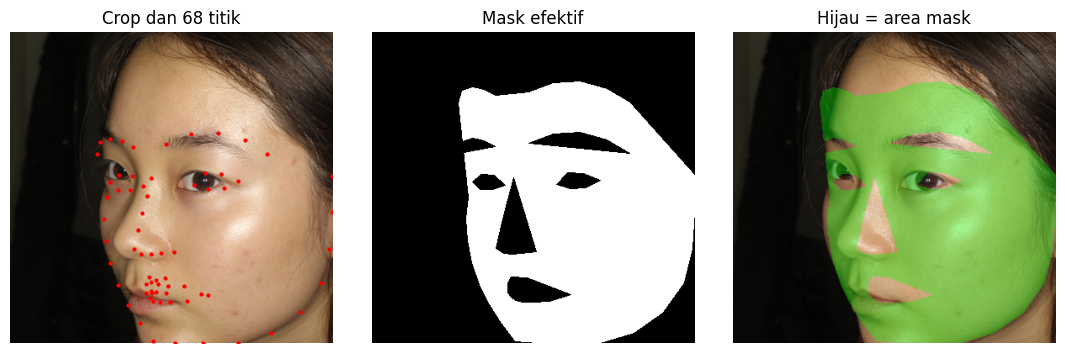

In [9]:
example_row = rows.loc[rows['split'] == 'train'].iloc[0]
example_crop, example_preview, example_haar_info = detect_and_crop(example_row)
example_mask, example_info, example_points = landmark_mask(example_crop)
for name, radii in RADIUS_OPTIONS.items():
    vector, fallbacks = extract_features(example_crop, example_mask, radii)
    print(name, '| fitur:', len(vector), '| fallback LBP:', fallbacks)
print('Status LBF:', example_info['landmark_reason'])

figure, axes = plt.subplots(1, 3, figsize=(11, 3.5))
axes[0].imshow(example_crop)
axes[0].set_title('Crop dan 68 titik')
if example_points is not None:
    axes[0].scatter(example_points[:, 0], example_points[:, 1], s=4, c='red')
axes[1].imshow(example_mask, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Mask efektif')
axes[2].imshow(overlay_mask(example_crop, example_mask))
axes[2].set_title('Hijau = area mask')
for axis in axes:
    axis.axis('off')
plt.tight_layout()
plt.savefig(OUT / 'lbf_example.png', dpi=120)
plt.show()

## 6. Hitung fitur seluruh train dan validation
Crop dan mask yang sama dipakai untuk kedua varian fitur. Setiap foto tetap masuk
evaluasi, termasuk fallback. Mask efektif disimpan sebagai PNG pada ukuran crop.
Proses LBP beberapa radius dapat memerlukan beberapa menit di CPU.

In [10]:
features = {'single_radius': [], 'multi_radius': []}
audit_records = []
for image_index, row in rows.iterrows():
    crop, preview, haar_info = detect_and_crop(row)
    mask, mask_info, points = landmark_mask(crop)
    single_vector, single_fallbacks = extract_features(crop, mask, [1])
    multi_vector, multi_fallbacks = extract_features(crop, mask, [1, 2, 3])
    features['single_radius'].append(single_vector)
    features['multi_radius'].append(multi_vector)

    mask_name = Path(row['filename']).stem + '.png'
    mask_path = OUT / 'masks' / row['split'] / mask_name
    mask_path.parent.mkdir(exist_ok=True)
    Image.fromarray(mask).save(mask_path)
    record = {
        'filename': row['filename'],
        'split': row['split'],
        'label': row['label'],
        'mask_fraction': float(np.mean(mask > 0)),
        'mask_path': str(mask_path.relative_to(PROJECT)),
    }
    record.update(haar_info)
    record.update(mask_info)
    for radius in [1, 2, 3]:
        record['lbp_fallback_r' + str(radius)] = multi_fallbacks[radius]
    audit_records.append(record)
    if (image_index + 1) % 100 == 0:
        print('Selesai', image_index + 1, '/', len(rows), flush=True)

features['single_radius'] = np.array(features['single_radius'])
features['multi_radius'] = np.array(features['multi_radius'])
assert features['single_radius'].shape == (len(rows), 58)
assert features['multi_radius'].shape == (len(rows), 102)
audit = pd.DataFrame(audit_records)
rows.to_csv(OUT / 'manifest.csv', index=False)
audit.to_csv(OUT / 'mask_audit.csv', index=False)
np.savez_compressed(OUT / 'features.npz', **features)
display(audit.groupby('split')[['detected', 'landmark_fallback',
                               'lbp_fallback_r1', 'lbp_fallback_r2', 'lbp_fallback_r3']].mean())
display(audit.groupby(['split', 'landmark_reason']).size().rename('images').to_frame())

Selesai 100 / 1199
Selesai 200 / 1199
Selesai 300 / 1199
Selesai 400 / 1199
Selesai 500 / 1199
Selesai 600 / 1199
Selesai 700 / 1199
Selesai 800 / 1199
Selesai 900 / 1199
Selesai 1000 / 1199
Selesai 1100 / 1199


,detected,landmark_fallback,lbp_fallback_r1,lbp_fallback_r2,lbp_fallback_r3
split,,,,,
train,0.611955,0.418440,0.0,0.0,0.0
val,0.570755,0.448113,0.0,0.0,0.0


images
split landmark_reason        
train no_face             413
      ok                  574
val   no_face              95
      ok                  117

### 6.1 Periksa beberapa contoh tiap kelas
Kolom pertama crop, kedua mask efektif, ketiga overlay. Contoh ini dipilih dari
train, bukan test. Overlay seluruhnya hijau bisa berarti fallback.
Deteksi berhasil bukan jaminan mask atau prediksi kelas benar.

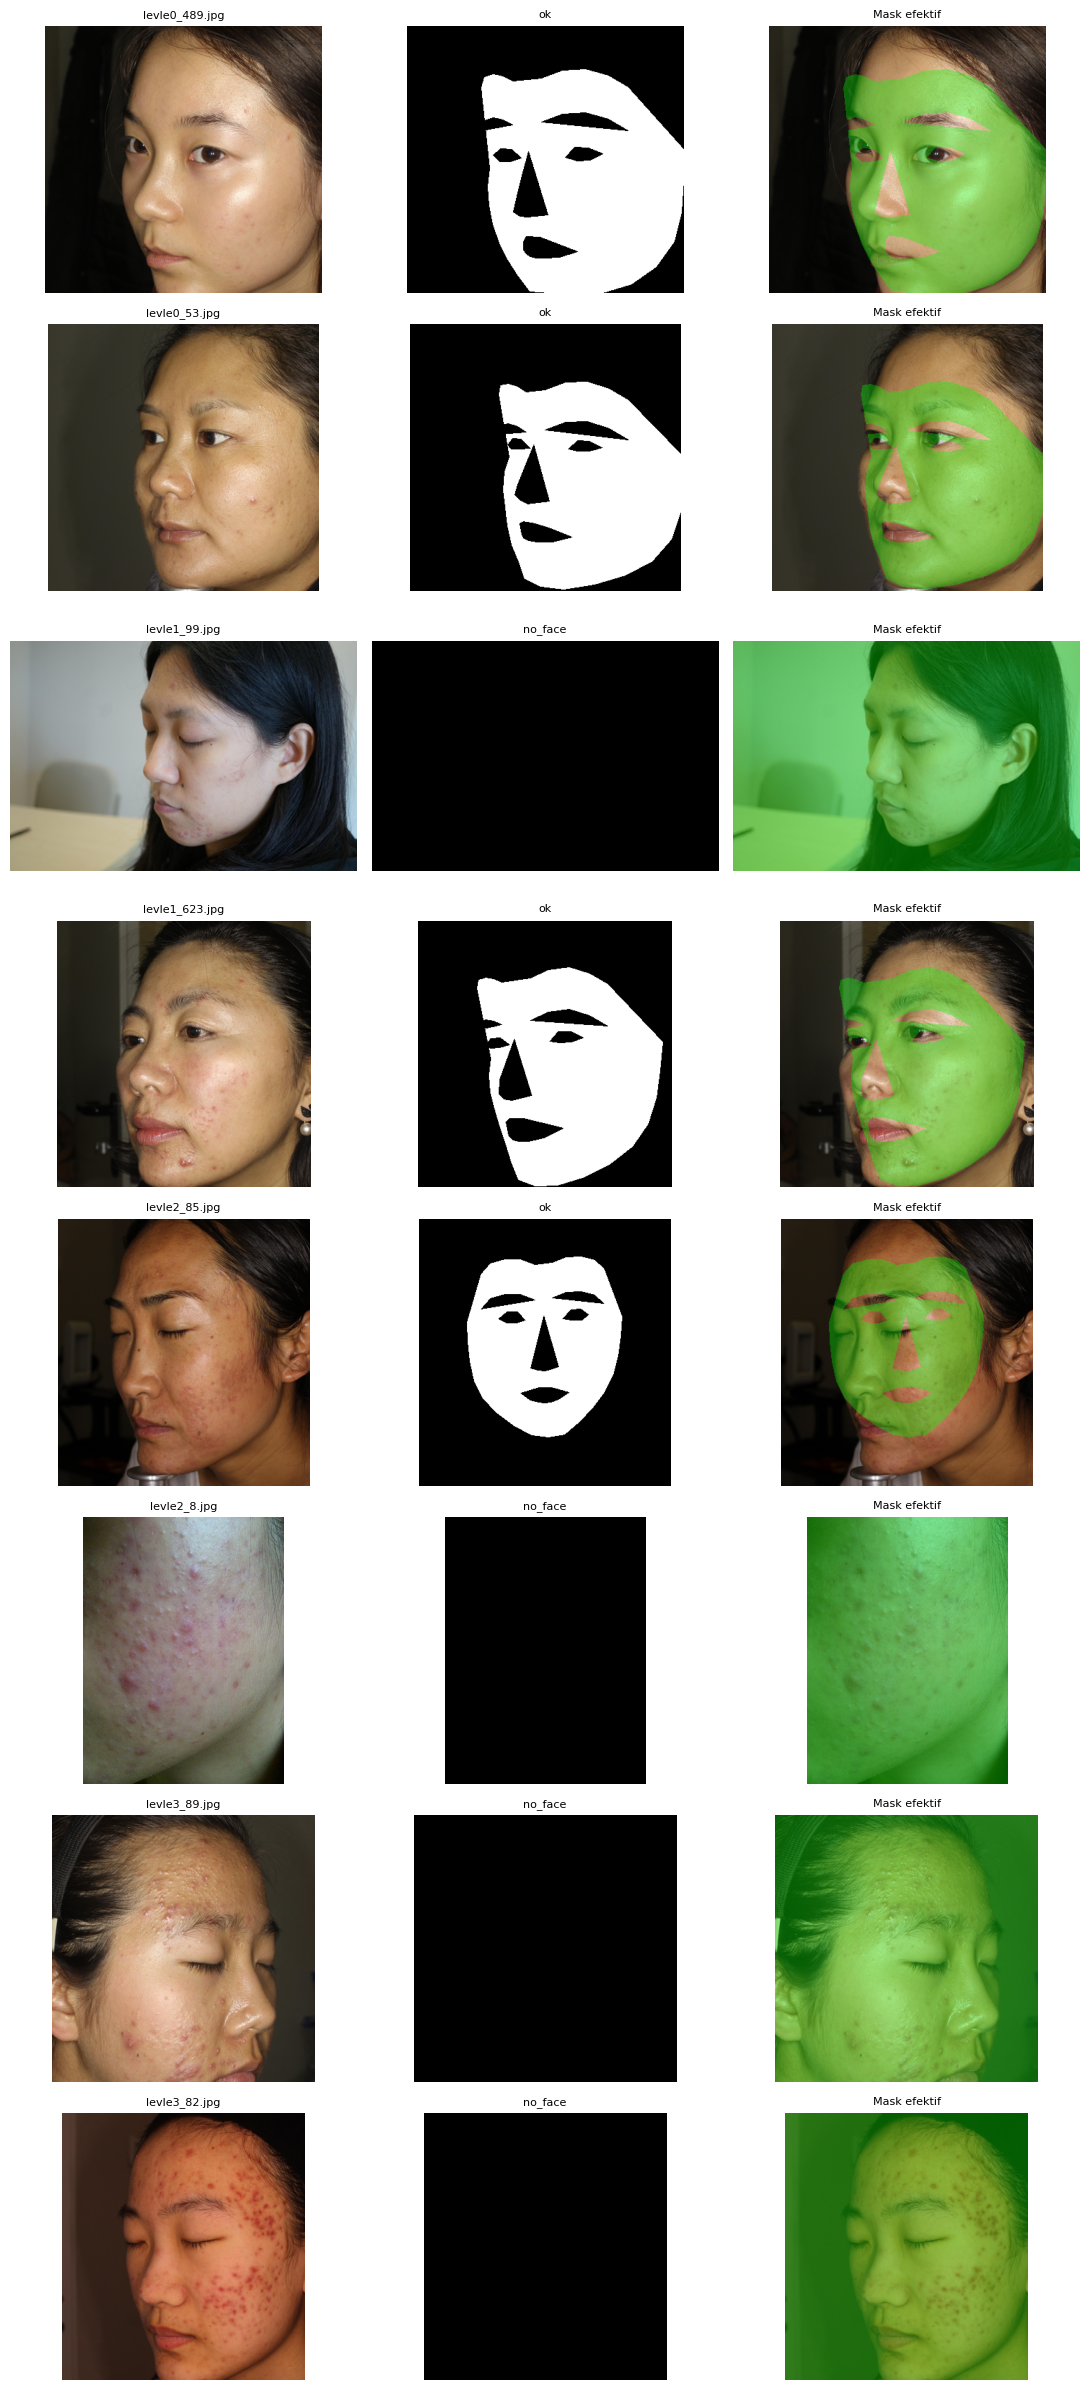

In [11]:
sample_groups = []
for label in range(4):
    selected = (rows['split'] == 'train') & (rows['label'] == label)
    sample_groups.append(rows.loc[selected].head(2))
samples = pd.concat(sample_groups)
figure, axes = plt.subplots(len(samples), 3, figsize=(11, 3 * len(samples)), squeeze=False)
for plot_index, row_data in enumerate(samples.iterrows()):
    row = row_data[1]
    crop, preview, haar_info = detect_and_crop(row)
    mask, mask_info, points = landmark_mask(crop)
    images = [crop, mask, overlay_mask(crop, mask)]
    titles = [row['filename'], mask_info['landmark_reason'], 'Mask efektif']
    for column in range(3):
        axes[plot_index, column].imshow(images[column], cmap='gray')
        axes[plot_index, column].set_title(titles[column], fontsize=8)
        axes[plot_index, column].axis('off')
plt.tight_layout()
plt.savefig(OUT / 'mask_examples.png', dpi=100)
plt.show()

## 7. Pisahkan train dan validation
**Hanya train yang digunakan untuk tuning.** Validation disimpan untuk perbandingan
akhir setelah pencarian parameter selesai. Scaler berada di dalam pipeline sehingga
selama cross-validation, scaler hanya belajar dari bagian training setiap fold.

In [12]:
train = rows['split'].to_numpy() == 'train'
validation = rows['split'].to_numpy() == 'val'
labels = rows['label'].to_numpy()
y_train = labels[train]
y_validation = labels[validation]
print('Train:', len(y_train), '| validation:', len(y_validation))

def build_model(c_value=10.0, gamma_value='scale'):
    scaler = StandardScaler()
    classifier = SVC(C=c_value, gamma=gamma_value, kernel='rbf', class_weight='balanced')
    return make_pipeline(scaler, classifier)

Train: 987 | validation: 212


## 8. Tuning C dan gamma dengan 5-fold cross-validation
Train dibagi menjadi lima fold. Empat fold untuk fit dan satu fold untuk penilaian,
bergantian lima kali. Rata-rata macro-F1 menentukan kombinasi terbaik.

- **C:** kompromi antara kelonggaran batas dan kesalahan pada train.
- **Gamma:** seberapa lokal pengaruh satu sampel pada kernel RBF.
- **`svc__C` / `svc__gamma`:** nama parameter SVC di dalam pipeline.

Ada 4 × 4 = **16 kombinasi**, masing-masing 5 fold. Dua varian berarti **160 fit CV**,
ditambah fit ulang konfigurasi terpilih pada seluruh train. Prosesnya akan lebih
lama dari notebook sebelumnya. `n_jobs=1` menjalankan proses satu per satu.

`random_state=42` membuat pembagian fold dapat diulang. Tidak ada parameter yang
dipilih berdasarkan validation. Jika tersedia ID pasien, gunakan pembagian
berdasarkan pasien; StratifiedKFold di sini menjaga proporsi kelas, bukan identitas.

In [13]:
parameter_grid = {
    'svc__C': [0.1, 1.0, 10.0, 100.0],
    'svc__gamma': ['scale', 0.001, 0.01, 0.1],
}
cross_validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
searches = {}
cv_records = []

for name in RADIUS_OPTIONS:
    print('Tuning:', name, flush=True)
    search = GridSearchCV(
        estimator=build_model(),
        param_grid=parameter_grid,
        scoring='f1_macro',
        cv=cross_validation,
        n_jobs=1,
        refit=True,
        error_score='raise',
        verbose=1,
    )
    search.fit(features[name][train], y_train)
    searches[name] = search

    table = pd.DataFrame(search.cv_results_)
    table.to_csv(OUT / ('cv_' + name + '.csv'), index=False)
    record = {
        'feature_set': name,
        'best_C': search.best_params_['svc__C'],
        'best_gamma': search.best_params_['svc__gamma'],
        'cv_macro_f1': search.best_score_,
        'cv_std': search.cv_results_['std_test_score'][search.best_index_],
    }
    cv_records.append(record)
    print('Terbaik:', search.best_params_, '| CV macro-F1:', round(search.best_score_, 4))

cv_summary = pd.DataFrame(cv_records)
cv_summary.to_csv(OUT / 'cv_best.csv', index=False)
display(cv_summary)

Tuning: single_radius
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Terbaik: {'svc__C': 100.0, 'svc__gamma': 0.01} | CV macro-F1: 0.4212
Tuning: multi_radius
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Terbaik: {'svc__C': 100.0, 'svc__gamma': 0.001} | CV macro-F1: 0.489


,feature_set,best_C,best_gamma,cv_macro_f1,cv_std
0,single_radius,100.0,0.010,0.421233,0.060362
1,multi_radius,100.0,0.001,0.489021,0.044670


## 9. Bandingkan pada validation
Empat baris berikut membantu membedakan pengaruh fitur dan tuning:

| Konfigurasi | Fitur | Parameter |
|---|---|---|
| `single_fixed` | Radius 1 + HSV | C=10, gamma=scale, parameter pembanding tetap |
| `multi_fixed` | Radius 1,2,3 + HSV | C=10, gamma=scale |
| `single_tuned` | Radius 1 + HSV | Terpilih dari CV train |
| `multi_tuned` | Radius 1,2,3 + HSV | Terpilih dari CV train |

Macro-F1 memberi bobot sama ke setiap kelas. Balanced accuracy merata-ratakan recall
per kelas. Accuracy adalah proporsi seluruh prediksi yang benar.
Tabel ini untuk membaca hasil; tidak dipakai mencari parameter tambahan.

In [14]:
models = {}
model_features = {}

for name in RADIUS_OPTIONS:
    if name == 'single_radius':
        prefix = 'single'
    else:
        prefix = 'multi'

    fixed_model = build_model()
    fixed_model.fit(features[name][train], y_train)
    models[prefix + '_fixed'] = fixed_model
    models[prefix + '_tuned'] = searches[name].best_estimator_
    model_features[prefix + '_fixed'] = name
    model_features[prefix + '_tuned'] = name

evaluation_order = ['single_fixed', 'multi_fixed', 'single_tuned', 'multi_tuned']
evaluation_records = []
validation_predictions = {}
for experiment in evaluation_order:
    feature_set = model_features[experiment]
    model = models[experiment]
    predictions = model.predict(features[feature_set][validation])
    validation_predictions[experiment] = predictions
    record = {
        'experiment': experiment,
        'feature_count': features[feature_set].shape[1],
        'C': model.named_steps['svc'].C,
        'gamma': model.named_steps['svc'].gamma,
        'macro_f1': f1_score(y_validation, predictions, average='macro', zero_division=0),
        'balanced_accuracy': balanced_accuracy_score(y_validation, predictions),
        'accuracy': accuracy_score(y_validation, predictions),
    }
    evaluation_records.append(record)

evaluation = pd.DataFrame(evaluation_records)
evaluation.to_csv(OUT / 'validation_comparison.csv', index=False)
display(evaluation.round(4))

,experiment,feature_count,C,gamma,macro_f1,balanced_accuracy,accuracy
0,single_fixed,58,10.0,scale,0.4786,0.4893,0.5000
1,multi_fixed,102,10.0,scale,0.5514,0.5395,0.5849
2,single_tuned,58,100.0,0.01,0.4976,0.4936,0.5142
3,multi_tuned,102,100.0,0.001,0.5037,0.4993,0.5566


### 9.1 Evaluasi lengkap model terpilih
`SELECTED_EXPERIMENT = 'multi_fixed'` mengikuti model yang dipakai notebook prediksi.
Ubah variabel ini untuk melihat konfigurasi lain; pemilihan ini tidak melakukan tuning ulang.
Semua angka di bawah dihitung pada **validation**, bukan train atau test.

**Accuracy tiap kelas (recall)** = jumlah prediksi benar untuk kelas tersebut / jumlah
sampel sebenarnya pada kelas tersebut, yaitu TP / (TP + FN). Kolom ini sama dengan recall.
**Accuracy one-vs-rest** = (TP + TN) / seluruh sampel; metrik ini turut menghitung
sampel kelas lain yang benar ditolak, sehingga dapat tinggi pada kelas yang jarang.
Precision, F1, specificity, support, serta TP/FN/FP/TN juga ditampilkan.

Confusion matrix: baris = kelas sebenarnya, kolom = prediksi. Matriks pertama
berisi jumlah sampel; matriks kedua dinormalisasi per baris sehingga diagonalnya
adalah recall tiap kelas. Semua tabel dan grafik disimpan ke folder hasil.

Model terpilih: multi_fixed
Split evaluasi: validation | jumlah sampel: 212


,experiment,feature_count,C,gamma,macro_f1,balanced_accuracy,accuracy
1,multi_fixed,102,10.0,scale,0.5514,0.5395,0.5849


Classification report (termasuk macro dan weighted average):


,precision,recall,f1-score,support
mild,0.5823,0.6133,0.5974,75.0000
moderate,0.6000,0.6264,0.6129,91.0000
severe,0.6316,0.4444,0.5217,27.0000
very_severe,0.4737,0.4737,0.4737,19.0000
accuracy,0.5849,0.5849,0.5849,0.5849
macro avg,0.5719,0.5395,0.5514,212.0000
weighted avg,0.5864,0.5849,0.5833,212.0000


Metrik tiap kelas (skala 0-1; kalikan 100 untuk persen):


,class,support,TP,FN,FP,TN,accuracy_per_class_recall,precision,recall,f1_score,specificity,accuracy_one_vs_rest
0,mild,75,46,29,33,104,0.6133,0.5823,0.6133,0.5974,0.7591,0.7075
1,moderate,91,57,34,38,83,0.6264,0.6000,0.6264,0.6129,0.6860,0.6604
2,severe,27,12,15,7,178,0.4444,0.6316,0.4444,0.5217,0.9622,0.8962
3,very_severe,19,9,10,10,183,0.4737,0.4737,0.4737,0.4737,0.9482,0.9057


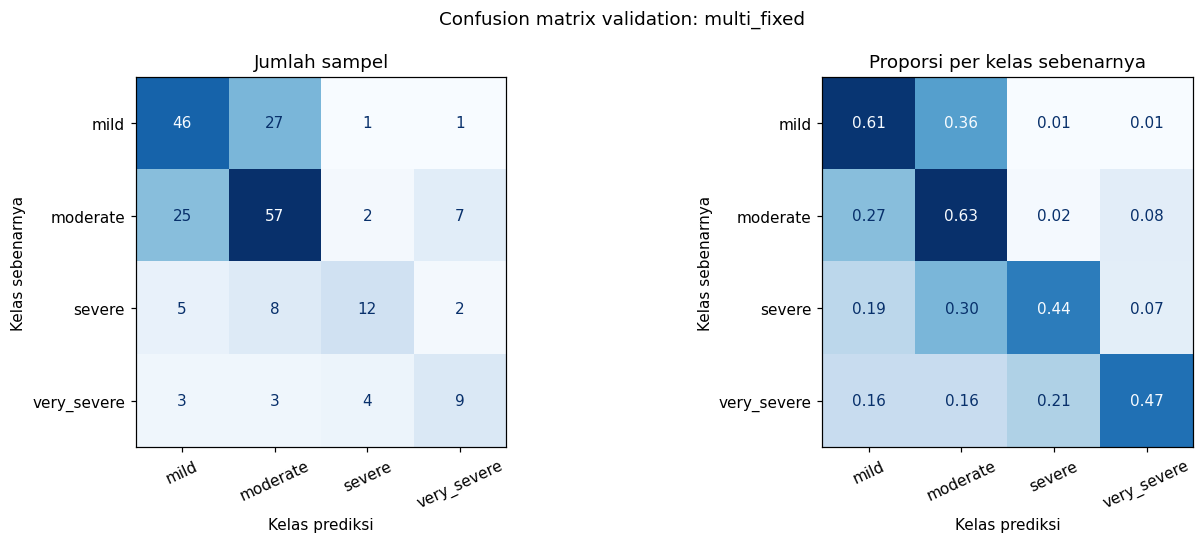

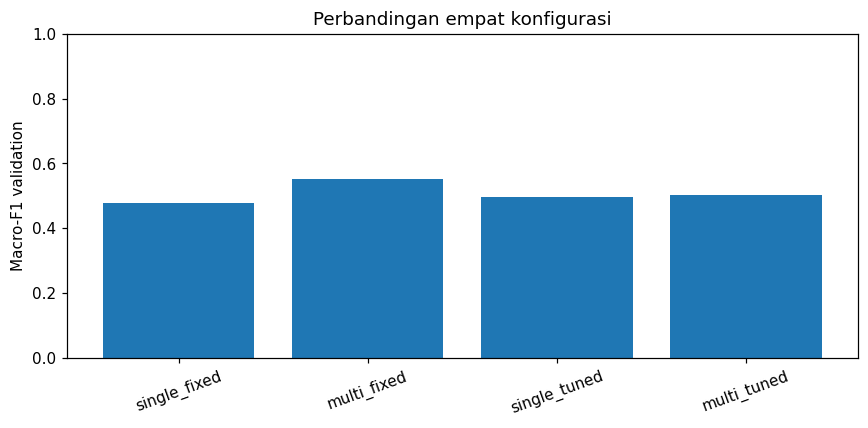

Efek penambahan radius (C-gamma tetap): 0.0729
Efek tuning pada multi-radius: -0.0477
Tabel dan grafik evaluasi tersimpan di: C:\Users\damar\KULIAH\S5\PBL2026\machine_learning\experiments\acne04_landmark\results_lbf_multiradius


In [ ]:
from sklearn.metrics import confusion_matrix

# Model yang digunakan pada notebook prediksi gambar baru.
SELECTED_EXPERIMENT = 'multi_fixed'
assert SELECTED_EXPERIMENT in validation_predictions, 'Nama model tidak tersedia.'
selected_predictions = validation_predictions[SELECTED_EXPERIMENT]
class_ids = [0, 1, 2, 3]
assert len(y_validation) == len(selected_predictions) > 0

selected_summary = evaluation.loc[
    evaluation['experiment'] == SELECTED_EXPERIMENT].copy()
print('Model terpilih:', SELECTED_EXPERIMENT)
print('Split evaluasi: validation | jumlah sampel:', len(y_validation))
display(selected_summary.round(4))
selected_summary.to_csv(OUT / ('evaluation_summary_' + SELECTED_EXPERIMENT + '.csv'), index=False)

report = classification_report(
    y_validation, selected_predictions, labels=class_ids,
    target_names=classes, zero_division=0, output_dict=True)
report_table = pd.DataFrame(report).transpose()
report_table.to_csv(OUT / ('classification_report_' + SELECTED_EXPERIMENT + '.csv'))
print('Classification report (termasuk macro dan weighted average):')
display(report_table.round(4))

cm = confusion_matrix(y_validation, selected_predictions, labels=class_ids)
support = cm.sum(axis=1)
tp = np.diag(cm)
fn = support - tp
fp = cm.sum(axis=0) - tp
tn = cm.sum() - tp - fn - fp
recall_per_class = np.divide(tp, support, out=np.zeros(4, dtype=float), where=support != 0)
specificity = np.divide(tn, tn + fp, out=np.zeros(4, dtype=float), where=(tn + fp) != 0)
per_class = pd.DataFrame({
    'class': classes,
    'support': support,
    'TP': tp, 'FN': fn, 'FP': fp, 'TN': tn,
    'accuracy_per_class_recall': recall_per_class,
    'precision': [report[name]['precision'] for name in classes],
    'recall': recall_per_class,
    'f1_score': [report[name]['f1-score'] for name in classes],
    'specificity': specificity,
    'accuracy_one_vs_rest': (tp + tn) / cm.sum(),
})
print('Metrik tiap kelas (skala 0-1; kalikan 100 untuk persen):')
display(per_class.round(4))
per_class.to_csv(OUT / ('per_class_metrics_' + SELECTED_EXPERIMENT + '.csv'), index=False)

cm_normalized = np.divide(
    cm, support[:, None], out=np.zeros_like(cm, dtype=float), where=support[:, None] != 0)
for suffix, matrix in [('', cm), ('_normalized', cm_normalized)]:
    matrix_table = pd.DataFrame(matrix, index=classes, columns=classes)
    matrix_table.index.name = 'actual_class'
    matrix_table.columns.name = 'predicted_class'
    matrix_table.to_csv(OUT / ('confusion_matrix_' + SELECTED_EXPERIMENT + suffix + '.csv'))

figure, axes = plt.subplots(1, 2, figsize=(13, 5))
for axis, matrix, title, value_format in [
    (axes[0], cm, 'Jumlah sampel', 'd'),
    (axes[1], cm_normalized, 'Proporsi per kelas sebenarnya', '.2f'),
]:
    ConfusionMatrixDisplay(matrix, display_labels=classes).plot(
        ax=axis, cmap='Blues', colorbar=False, xticks_rotation=25,
        values_format=value_format)
    axis.set_title(title)
    axis.set_xlabel('Kelas prediksi')
    axis.set_ylabel('Kelas sebenarnya')
figure.suptitle('Confusion matrix validation: ' + SELECTED_EXPERIMENT)
plt.tight_layout()
plt.savefig(OUT / ('confusion_matrix_' + SELECTED_EXPERIMENT + '.png'), dpi=140)
plt.show()

figure, axis = plt.subplots(figsize=(8, 4))
axis.bar(evaluation['experiment'], evaluation['macro_f1'])
axis.set_ylim(0, 1)
axis.set_ylabel('Macro-F1 validation')
axis.tick_params(axis='x', labelrotation=20)
axis.set_title('Perbandingan empat konfigurasi')
plt.tight_layout()
plt.savefig(OUT / 'validation_comparison.png', dpi=140)
plt.show()

scores = evaluation.set_index('experiment')['macro_f1']
print('Efek penambahan radius (C-gamma tetap):', round(scores['multi_fixed'] - scores['single_fixed'], 4))
print('Efek tuning pada multi-radius:', round(scores['multi_tuned'] - scores['multi_fixed'], 4))
print('Tabel dan grafik evaluasi tersimpan di:', OUT)


## 10. Simpan model dan konfigurasi preprocessing
Simpan pipeline scaler + SVM setiap konfigurasi. Model multi-radius menerima
**102 fitur**, sehingga tidak bisa langsung dipakai pada notebook prediksi lama
yang mengambil 58 fitur. Saat membuat prediksi baru, gunakan `extract_features()`
dan urutan radius dari konfigurasi yang disimpan.

Tidak ada fit pada validation dan tidak ada evaluasi ulang test.

In [16]:
predictor_hash = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()

for experiment in evaluation_order:
    feature_set = model_features[experiment]
    joblib.dump(models[experiment], OUT / 'models' / (experiment + '.joblib'))

    prediction_table = rows.loc[validation, ['filename', 'label']].copy()
    prediction_table['prediction'] = validation_predictions[experiment]
    prediction_table.to_csv(OUT / ('predictions_' + experiment + '.csv'), index=False)

    settings = {
        'feature_set': feature_set,
        'lbp_radii': RADIUS_OPTIONS[feature_set],
        'lbp_neighbors': '8 * radius',
        'lbp_method': 'uniform',
        'lbp_min_interior_pixels': 100,
        'lbp_fallback': 'full crop interior for the affected radius only',
        'hsv_bins_per_channel': 16,
        'feature_count': int(features[feature_set].shape[1]),
        'feature_order': 'LBP in ascending radius order, H, S, V',
        'landmark_method': 'opencv_facemark_lbf_68',
        'landmark_options': CONFIG,
        'landmark_predictor_file': MODEL_PATH.name,
        'landmark_predictor_sha256': predictor_hash,
        'forehead_method': 'reversed eyebrow points shifted upward by forehead_ratio * brow_to_chin_height',
        'haar_scale_factor': 1.1,
        'haar_min_neighbors': 5,
        'haar_min_size': [40, 40],
        'haar_margin': 0.15,
        'jpeg_draft_size': 768,
        'haar_detection_max_side': 640,
        'crop_max_side': 384,
        'C': models[experiment].named_steps['svc'].C,
        'gamma': models[experiment].named_steps['svc'].gamma,
    }
    settings_path = OUT / 'models' / (experiment + '_config.json')
    settings_path.write_text(json.dumps(settings, indent=2), encoding='utf-8')

metadata = {
    'python': platform.python_version(),
    'opencv': cv2.__version__,
    'numpy': np.__version__,
    'scikit_learn': importlib.metadata.version('scikit-learn'),
    'manifest_sha256': hashlib.sha256((PREVIOUS / 'manifest_with_roi.csv').read_bytes()).hexdigest(),
    'cascade_sha256': hashlib.sha256(cascade_path.read_bytes()).hexdigest(),
    'cv_folds': 5,
    'cv_random_state': 42,
    'parameter_grid': parameter_grid,
    'landmark_options': CONFIG,
    'landmark_method': 'opencv_facemark_lbf_68',
    'landmark_predictor_sha256': predictor_hash,
}
(OUT / 'run_metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
print('Hasil baru tersimpan di:', OUT)
print('Model lama tidak ditimpa. Test tidak dievaluasi ulang.')

Hasil baru tersimpan di: c:\Users\damar\KULIAH\S5\PBL2026\machine_learning\experiments\acne04_landmark\results_lbf_multiradius
Model lama tidak ditimpa. Test tidak dievaluasi ulang.


## 11. Cara membaca kesimpulan
- Jika `multi_fixed` lebih baik dari `single_fixed`, penambahan radius membantu
  pada validation ini dengan parameter SVM yang sama.
- Jika `multi_tuned` lebih baik dari `multi_fixed`, tuning membantu pada validation ini.
- Periksa CV mean dan simpangan bakunya, hasil per kelas, serta fallback radius besar.
- Tidak semua konfigurasi akan membaik. Penambahan fitur dapat membawa informasi
  tambahan sekaligus gangguan.
- Validation ini sudah pernah dilihat. Skor tertinggi tidak membuktikan peningkatan
  generalisasi; evaluasi final membutuhkan data independen atau nested CV.

Output utama: `validation_comparison.csv`, `cv_best.csv`, tabel seluruh hasil CV,
`features.npz`, audit fallback, grafik, dan model/config di `results_lbf_multiradius/`.

## 12. Bandingkan dengan eksperimen MediaPipe sebelumnya
Jika hasil MediaPipe tersedia, tampilkan skor pada split yang sama.
Fitur LBF **tidak diharapkan sama** karena mask berubah.
Perbandingan ini tidak dipakai untuk menyesuaikan parameter dahi atau mencari C–gamma.
Model LBF harus dievaluasi ulang; model MediaPipe tidak langsung digunakan.

In [17]:
previous_scores = OLD_RESULTS / 'validation_comparison.csv'
if previous_scores.is_file():
    old_table = pd.read_csv(previous_scores)
    old_table['landmark_method'] = 'MediaPipe'
    new_table = evaluation.copy()
    new_table['landmark_method'] = 'LBF 68'
    comparison = pd.concat([old_table, new_table], ignore_index=True)
    comparison.to_csv(OUT / 'comparison_with_mediapipe.csv', index=False)
    display(comparison[['landmark_method', 'experiment', 'macro_f1', 'balanced_accuracy', 'accuracy']].round(4))
else:
    print('Hasil MediaPipe sebelumnya tidak tersedia; perbandingan dilewati.')

,landmark_method,experiment,macro_f1,balanced_accuracy,accuracy
0,MediaPipe,single_fixed,0.5122,0.5330,0.5189
1,MediaPipe,multi_fixed,0.5735,0.5735,0.5896
2,MediaPipe,single_tuned,0.5424,0.5411,0.5472
3,MediaPipe,multi_tuned,0.5832,0.5808,0.5943
4,LBF 68,single_fixed,0.4786,0.4893,0.5000
5,LBF 68,multi_fixed,0.5514,0.5395,0.5849
6,LBF 68,single_tuned,0.4976,0.4936,0.5142
7,LBF 68,multi_tuned,0.5037,0.4993,0.5566
